# HbA1c — Full-cohort inferential replication

This notebook replicates the analysis described by Strack et al., *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records*, DOI: [10.1155/2014/781670](https://doi.org/10.1155/2014/781670).

It includes cohort selection, descriptive tables, four logistic-regression specifications, coefficient estimates, odds ratios and paper figures.

The final interaction model is fitted to the full eligible analysis cohort. Confidence intervals describe uncertainty in estimated associations and predicted probabilities; they do not measure held-out predictive performance.

The encounter-level age figure uses its separately defined cohort, as specified in the replication.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from patsy import build_design_matrices

data_path = "../../data/hba1c/diabetic_data_initial.csv"
map_path = "../../data/hba1c/id_mapping.csv"

df = pd.read_csv(data_path, keep_default_na=False)
idmap_raw = pd.read_csv(map_path, keep_default_na=False)



In [2]:
# Parse the identifier mapping file.
idmap_raw.columns = ["id", "description"]
idmap_raw["id"] = idmap_raw["id"].astype(str).str.strip()
idmap_raw["description"] = idmap_raw["description"].astype(str).str.strip()


In [3]:
def parse_id_mapping(idmap_raw):
    """Parse the source identifier mapping into named lookup tables."""
    sections = {}
    current_section = None
    current_rows = []

    for _, row in idmap_raw.iterrows():
        left = str(row["id"]).strip()
        right = str(row["description"]).strip()

        if left in ["nan", "ID mappings for the diabetes dataset"]:
            continue
        if right in ["nan", "? - always means a missing value"]:
            continue

        if left in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
            if current_section is not None and current_rows:
                sections[current_section] = pd.DataFrame(current_rows, columns=["id", "description"])
            current_section = left
            current_rows = []
            continue

        if left == "description" or right == "description":
            continue

        try:
            key = int(float(left))
            current_rows.append((key, right))
        except Exception:
            pass

    if current_section is not None and current_rows:
        sections[current_section] = pd.DataFrame(current_rows, columns=["id", "description"])

    return sections

sections = parse_id_mapping(idmap_raw)


In [4]:
admission_type_map = dict(zip(sections["admission_type_id"]["id"], sections["admission_type_id"]["description"]))
discharge_map = dict(zip(sections["discharge_disposition_id"]["id"], sections["discharge_disposition_id"]["description"]))
admission_source_map = dict(zip(sections["admission_source_id"]["id"], sections["admission_source_id"]["description"]))


In [5]:
# Apply the source-study preprocessing.
df2 = df.copy()

# Define readmission within 30 days as the outcome.
df2["readmitted_bin"] = (df2["readmitted"] == "<30").astype(int)

# Remove variables excluded by the source study.
df2 = df2.drop(columns=["weight", "payer_code"], errors="ignore")

# Standardise the source missing-value markers.
df2["medical_specialty"] = df2["medical_specialty"].replace("?", np.nan).fillna("missing")
df2["race"] = df2["race"].replace("?", np.nan).fillna("Missing")

# Add readable descriptions for coded fields.
df2["discharge_desc"] = df2["discharge_disposition_id"].map(discharge_map)
df2["admission_type_desc"] = df2["admission_type_id"].map(admission_type_map)
df2["admission_source_desc"] = df2["admission_source_id"].map(admission_source_map)

# Retain the first encounter for each patient.
# Preserve the complete first encounter rather than combining rows.
df2 = (
    df2.sort_values(["patient_nbr", "encounter_id"])
       .drop_duplicates(subset="patient_nbr", keep="first")
       .copy()
)

# Exclude invalid or unknown gender records.
df2 = df2[df2["gender"].isin(["Female", "Male"])].copy()

# Exclude discharge dispositions associated with death or hospice.
death_hospice_ids = [11, 13, 14, 19, 20, 21]
df2 = df2[~df2["discharge_disposition_id"].isin(death_hospice_ids)].copy()

print("Shape after cohort selection:", df2.shape)


Shape after cohort selection: (69970, 52)


In [6]:
# Construct the derived variables.
def make_hba1c_group(row):
    """Assign the study-defined HbA1c and medication-change group."""
    a1c = str(row["A1Cresult"]).strip()
    change = str(row["change"]).strip()

    if a1c == "None":
        return "No test was performed"
    elif a1c in ["Norm", ">7"]:
        return "Normal result of the test"
    elif a1c == ">8" and change == "No":
        return "Result was high but the diabetic medication was not changed"
    elif a1c == ">8" and change == "Ch":
        return "Result was high and the diabetic medication was changed"
    else:
        return np.nan



df2["hba1c_group"] = df2.apply(make_hba1c_group, axis=1)


In [7]:
df2["discharge_group"] = np.where(
    df2["discharge_disposition_id"] == 1,
    "Discharged to home",
    "Otherwise"
)


In [8]:
def map_admission_source(x):
    """Map an admission-source identifier to the study category."""
    if x == 7:
        return "Admitted from emergency room"
    elif x in [1, 2, 3]:
        return "Admitted because of physician/clinic referral"
    else:
        return "Otherwise"

df2["admission_source_group"] = df2["admission_source_id"].apply(map_admission_source)


In [9]:
def map_specialty(x):
    """Collapse a medical specialty into the study categories."""
    if x == "InternalMedicine":
        return "Internal Medicine"
    elif x == "Cardiology":
        return "Cardiology"
    elif "Surgery" in str(x):
        return "Surgery"
    elif x in ["Family/GeneralPractice", "FamilyPractice"]:
        return "Family/general practice"
    elif x == "missing":
        return "Missing or unknown"
    else:
        return "Other"

df2["specialty_group"] = df2["medical_specialty"].apply(map_specialty)


In [10]:
def map_race(x):
    """Map race values to the study categories."""
    if x == "AfricanAmerican":
        return "African American"
    elif x == "Caucasian":
        return "Caucasian"
    elif x == "Missing":
        return "Missing"
    else:
        return "Other"

df2["race_group"] = df2["race"].apply(map_race)


In [11]:
def age_midpoint(age_str):
    """Convert an age interval to its numeric midpoint."""
    nums = [int(x) for x in str(age_str).replace("[", "").replace(")", "").split("-") if x.isdigit()]
    if len(nums) == 2:
        return (nums[0] + nums[1]) / 2
    return np.nan

df2["age_mid"] = df2["age"].apply(age_midpoint)

def map_age_group3(x):
    """Assign a numeric age to one of the three study groups."""
    if pd.isna(x):
        return np.nan
    elif x <= 30:
        return "30 years old or younger"
    elif x <= 60:
        return "30-60 years old"
    else:
        return "Older than 60"

df2["age_group3"] = df2["age_mid"].apply(map_age_group3)


In [12]:
def group_primary_diag(code):
    """Map a primary diagnosis code to the study category."""
    code = str(code).strip()

    if code.startswith("V") or code.startswith("E"):
        return "Other"
    if code.startswith("250"):
        return "Diabetes"

    m = re.match(r"^(\d+)", code)
    if not m:
        return "Other"

    num = int(m.group(1))

    if 390 <= num <= 459 or num == 785:
        return "Circulatory"
    elif 460 <= num <= 519 or num == 786:
        return "Respiratory"
    elif 520 <= num <= 579 or num == 787:
        return "Digestive"
    elif 800 <= num <= 999:
        return "Injury"
    elif 710 <= num <= 739:
        return "Musculoskeletal"
    elif 580 <= num <= 629 or num == 788:
        return "Genitourinary"
    elif 140 <= num <= 239:
        return "Neoplasms"
    else:
        return "Other"

df2["primary_diag_group"] = df2["diag_1"].apply(group_primary_diag)


In [13]:
# Construct the final analysis cohort.
df2["hba1c_group"] = df2.apply(make_hba1c_group, axis=1)

analysis_df = df2[[
    "readmitted_bin",
    "hba1c_group",
    "gender",
    "discharge_group",
    "admission_source_group",
    "specialty_group",
    "primary_diag_group",
    "race_group",
    "age_group3",
    "age_mid",
    "time_in_hospital"
]].dropna().copy()

print("analysis_df shape:", analysis_df.shape)
print(analysis_df["hba1c_group"].value_counts(dropna=False))


analysis_df shape: (69970, 11)
hba1c_group
No test was performed                                          57125
Normal result of the test                                       6606
Result was high and the diabetic medication was changed         4058
Result was high but the diabetic medication was not changed     2181
Name: count, dtype: int64


In [14]:
def make_table3_block(df, col):
    """Summarise encounter counts and readmissions for one variable."""
    out = df.groupby(col).agg(
        n_encounters=("readmitted_bin", "size"),
        readmitted_n=("readmitted_bin", "sum")
    ).reset_index()

    out["pct_population"] = 100 * out["n_encounters"] / len(df)
    out["pct_in_group"] = 100 * out["readmitted_n"] / out["n_encounters"]
    return out

print(make_table3_block(analysis_df, "hba1c_group"))
print(make_table3_block(analysis_df, "gender"))
print(make_table3_block(analysis_df, "discharge_group"))
print(make_table3_block(analysis_df, "admission_source_group"))
print(make_table3_block(analysis_df, "specialty_group"))
print(make_table3_block(analysis_df, "primary_diag_group"))
print(make_table3_block(analysis_df, "race_group"))
print(make_table3_block(analysis_df, "age_group3"))

print(
    analysis_df[["age_mid", "time_in_hospital"]]
    .describe(percentiles=[0.25, 0.5, 0.75])
)


                                         hba1c_group  n_encounters  \
0                              No test was performed         57125   
1                          Normal result of the test          6606   
2  Result was high and the diabetic medication wa...          4058   
3  Result was high but the diabetic medication wa...          2181   

   readmitted_n  pct_population  pct_in_group  
0          5199       81.642132      9.101094  
1           569        9.441189      8.613382  
2           348        5.799628      8.575653  
3           161        3.117050      7.381935  
   gender  n_encounters  readmitted_n  pct_population  pct_in_group
0  Female         37229          3361       53.207089      9.027908
1    Male         32741          2916       46.792911      8.906264
      discharge_group  n_encounters  readmitted_n  pct_population  \
0  Discharged to home         44315          3078       63.334286   
1           Otherwise         25655          3199       36.665714  

In [15]:
table2_rep = (
    analysis_df["primary_diag_group"]
    .value_counts()
    .rename_axis("group_name")
    .reset_index(name="n_encounters")
)
table2_rep["pct_encounter"] = 100 * table2_rep["n_encounters"] / table2_rep["n_encounters"].sum()

print(table2_rep)


        group_name  n_encounters  pct_encounter
0      Circulatory         21383      30.560240
1            Other         12132      17.338860
2      Respiratory          9486      13.557239
3        Digestive          6487       9.271116
4         Diabetes          5748       8.214949
5           Injury          4692       6.705731
6  Musculoskeletal          4064       5.808204
7    Genitourinary          3440       4.916393
8        Neoplasms          2538       3.627269


In [16]:
analysis_df["discharge_group"] = pd.Categorical(
    analysis_df["discharge_group"],
    categories=["Discharged to home", "Otherwise"]
)

analysis_df["race_group"] = pd.Categorical(
    analysis_df["race_group"],
    categories=["African American", "Caucasian", "Missing", "Other"]
)

analysis_df["admission_source_group"] = pd.Categorical(
    analysis_df["admission_source_group"],
    categories=[
        "Admitted from emergency room",
        "Admitted because of physician/clinic referral",
        "Otherwise"
    ]
)

analysis_df["specialty_group"] = pd.Categorical(
    analysis_df["specialty_group"],
    categories=[
        "Cardiology",
        "Family/general practice",
        "Internal Medicine",
        "Missing or unknown",
        "Other",
        "Surgery"
    ]
)

analysis_df["age_group3"] = pd.Categorical(
    analysis_df["age_group3"],
    categories=[
        "30-60 years old",
        "Older than 60",
        "30 years old or younger"
    ]
)

analysis_df["primary_diag_group"] = pd.Categorical(
    analysis_df["primary_diag_group"],
    categories=[
        "Diabetes",
        "Circulatory",
        "Digestive",
        "Genitourinary",
        "Injury",
        "Musculoskeletal",
        "Neoplasms",
        "Other",
        "Respiratory"
    ]
)



analysis_df["hba1c_group"] = pd.Categorical(
    analysis_df["hba1c_group"],
    categories=[
        "No test was performed",
        "Normal result of the test",
        "Result was high and the diabetic medication was changed",
        "Result was high but the diabetic medication was not changed"
    ],
    ordered=True
)


In [17]:
# Apply the categorical levels used by the fitted formula.
cat_cols = [
    "hba1c_group", "gender", "discharge_group", "admission_source_group",
    "specialty_group", "primary_diag_group", "race_group", "age_group3"
]

for c in cat_cols:
    analysis_df[c] = analysis_df[c].astype("category")


In [18]:
print(analysis_df["gender"].cat.categories)
print(analysis_df["race_group"].cat.categories)
print(analysis_df["admission_source_group"].cat.categories)
print(analysis_df["discharge_group"].cat.categories)
print(analysis_df["specialty_group"].cat.categories)
print(analysis_df["age_group3"].cat.categories)
print(analysis_df["primary_diag_group"].cat.categories)
print(analysis_df["hba1c_group"].cat.categories)


Index(['Female', 'Male'], dtype='object')
Index(['African American', 'Caucasian', 'Missing', 'Other'], dtype='object')
Index(['Admitted from emergency room',
       'Admitted because of physician/clinic referral', 'Otherwise'],
      dtype='object')
Index(['Discharged to home', 'Otherwise'], dtype='object')
Index(['Cardiology', 'Family/general practice', 'Internal Medicine',
       'Missing or unknown', 'Other', 'Surgery'],
      dtype='object')
Index(['30-60 years old', 'Older than 60', '30 years old or younger'], dtype='object')
Index(['Diabetes', 'Circulatory', 'Digestive', 'Genitourinary', 'Injury',
       'Musculoskeletal', 'Neoplasms', 'Other', 'Respiratory'],
      dtype='object')
Index(['No test was performed', 'Normal result of the test',
       'Result was high and the diabetic medication was changed',
       'Result was high but the diabetic medication was not changed'],
      dtype='object')


In [19]:
core_model = smf.logit(
    "readmitted_bin ~ gender + race_group + admission_source_group + "
    "discharge_group + specialty_group + primary_diag_group + "
    "age_group3 + time_in_hospital",
    data=analysis_df
).fit(maxiter=200)

print(core_model.summary())


Optimization terminated successfully.
         Current function value: 0.296152
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:         readmitted_bin   No. Observations:                69970
Model:                          Logit   Df Residuals:                    69946
Method:                           MLE   Df Model:                           23
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                 0.01893
Time:                        14:40:41   Log-Likelihood:                -20722.
converged:                       True   LL-Null:                       -21122.
Covariance Type:            nonrobust   LLR p-value:                4.272e-154
                                                                              coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------

In [20]:
model_hba1c = smf.logit(
    "readmitted_bin ~ gender + race_group + admission_source_group + "
    "discharge_group + specialty_group + primary_diag_group + "
    "age_group3 + time_in_hospital + hba1c_group",
    data=analysis_df
).fit()

print(model_hba1c.summary())


Optimization terminated successfully.
         Current function value: 0.296090
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:         readmitted_bin   No. Observations:                69970
Model:                          Logit   Df Residuals:                    69943
Method:                           MLE   Df Model:                           26
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                 0.01913
Time:                        14:40:50   Log-Likelihood:                -20717.
converged:                       True   LL-Null:                       -21122.
Covariance Type:            nonrobust   LLR p-value:                1.230e-153
                                                                                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------

In [21]:
model_cov_int = smf.logit(
    "readmitted_bin ~ gender + race_group + admission_source_group + "
    "discharge_group + specialty_group + primary_diag_group + "
    "age_group3 + time_in_hospital + hba1c_group + "
    "discharge_group:race_group + "
    "discharge_group:specialty_group + "
    "discharge_group:primary_diag_group + "
    "discharge_group:time_in_hospital + "
    "specialty_group:time_in_hospital + "
    "specialty_group:age_group3 + "
    "primary_diag_group:time_in_hospital",
    data=analysis_df
).fit()

print(model_cov_int.summary())


Optimization terminated successfully.
         Current function value: 0.295010
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:         readmitted_bin   No. Observations:                69970
Model:                          Logit   Df Residuals:                    69903
Method:                           MLE   Df Model:                           66
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                 0.02271
Time:                        14:41:14   Log-Likelihood:                -20642.
converged:                       True   LL-Null:                       -21122.
Covariance Type:            nonrobust   LLR p-value:                1.166e-158
                                                                                       coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------

In [22]:
final_model = smf.logit(
    "readmitted_bin ~ gender + race_group + admission_source_group + "
    "discharge_group + specialty_group + primary_diag_group + "
    "age_group3 + time_in_hospital + hba1c_group + "
    "discharge_group:race_group + "
    "discharge_group:specialty_group + "
    "discharge_group:primary_diag_group + "
    "discharge_group:time_in_hospital + "
    "specialty_group:time_in_hospital + "
    "specialty_group:age_group3 + "
    "primary_diag_group:time_in_hospital + "
    "primary_diag_group:hba1c_group",
    data=analysis_df
).fit(maxiter=200)

print(final_model.summary())


Optimization terminated successfully.
         Current function value: 0.294692
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:         readmitted_bin   No. Observations:                69970
Model:                          Logit   Df Residuals:                    69879
Method:                           MLE   Df Model:                           90
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                 0.02377
Time:                        14:41:17   Log-Likelihood:                -20620.
converged:                       True   LL-Null:                       -21122.
Covariance Type:            nonrobust   LLR p-value:                2.685e-154
                                                                                                                       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------

In [23]:
params = core_model.params
conf = core_model.conf_int()

or_table = pd.DataFrame({
    "OR": np.exp(params),
    "2.5%": np.exp(conf[0]),
    "97.5%": np.exp(conf[1])
})

print(or_table)


                                                          OR      2.5%  \
Intercept                                           0.054186  0.045508   
gender[T.Male]                                      1.028692  0.975721   
race_group[T.Caucasian]                             1.017377  0.947802   
race_group[T.Missing]                               0.830316  0.690576   
race_group[T.Other]                                 0.917537  0.792711   
admission_source_group[T.Admitted because of ph...  0.983676  0.924341   
admission_source_group[T.Otherwise]                 0.877440  0.809683   
discharge_group[T.Otherwise]                        1.715480  1.619745   
specialty_group[T.Family/general practice]          1.316331  1.128064   
specialty_group[T.Internal Medicine]                1.321864  1.150626   
specialty_group[T.Missing or unknown]               1.177337  1.035876   
specialty_group[T.Other]                            1.098485  0.955354   
specialty_group[T.Surgery]            

In [24]:
# Use the cohort mean length of stay, matching the source analysis.
mean_los = analysis_df["time_in_hospital"].mean()

fig1_grid = pd.DataFrame({
    "primary_diag_group": [
        "Diabetes", "Diabetes", "Diabetes", "Diabetes",
        "Respiratory", "Respiratory", "Respiratory", "Respiratory",
        "Circulatory", "Circulatory", "Circulatory", "Circulatory"
    ],
    "hba1c_group": [
        "No test was performed",
        "Normal result of the test",
        "Result was high and the diabetic medication was changed",
        "Result was high but the diabetic medication was not changed"
    ] * 3,
    "gender": ["Female"] * 12,
    "race_group": ["African American"] * 12,
    "admission_source_group": ["Admitted from emergency room"] * 12,
    "discharge_group": ["Discharged to home"] * 12,
    "specialty_group": ["Cardiology"] * 12,
    "age_group3": ["30-60 years old"] * 12,
    "time_in_hospital": [mean_los] * 12
})


def apply_model_categories(new_df, model):
    """Align categorical levels with the fitted Patsy design information."""
    for factor, info in model.model.data.design_info.factor_infos.items():
        col = factor.name()
        if col in new_df.columns and info.type == "categorical":
            new_df[col] = pd.Categorical(new_df[col], categories=info.categories)
    return new_df

fig1_grid = apply_model_categories(fig1_grid, final_model)

X_new = build_design_matrices(
    [final_model.model.data.design_info],
    fig1_grid,
    return_type="dataframe"
)[0]

linpred = np.dot(X_new, final_model.params)

cov = final_model.cov_params()
se_linpred = np.sqrt(np.sum(np.dot(X_new, cov) * X_new, axis=1))

# Calculate the 95% confidence interval on the logit scale.
z = 1.96
linpred_lower = linpred - z * se_linpred
linpred_upper = linpred + z * se_linpred

invlogit = lambda x: 1 / (1 + np.exp(-x))

fig1_grid["pred_prob"] = invlogit(linpred)
fig1_grid["lower_ci"] = invlogit(linpred_lower)
fig1_grid["upper_ci"] = invlogit(linpred_upper)

print(fig1_grid[["primary_diag_group", "hba1c_group", "pred_prob", "lower_ci", "upper_ci"]])


   primary_diag_group                                        hba1c_group  \
0            Diabetes                              No test was performed   
1            Diabetes                          Normal result of the test   
2            Diabetes  Result was high and the diabetic medication wa...   
3            Diabetes  Result was high but the diabetic medication wa...   
4         Respiratory                              No test was performed   
5         Respiratory                          Normal result of the test   
6         Respiratory  Result was high and the diabetic medication wa...   
7         Respiratory  Result was high but the diabetic medication wa...   
8         Circulatory                              No test was performed   
9         Circulatory                          Normal result of the test   
10        Circulatory  Result was high and the diabetic medication wa...   
11        Circulatory  Result was high but the diabetic medication wa...   

    pred_pr

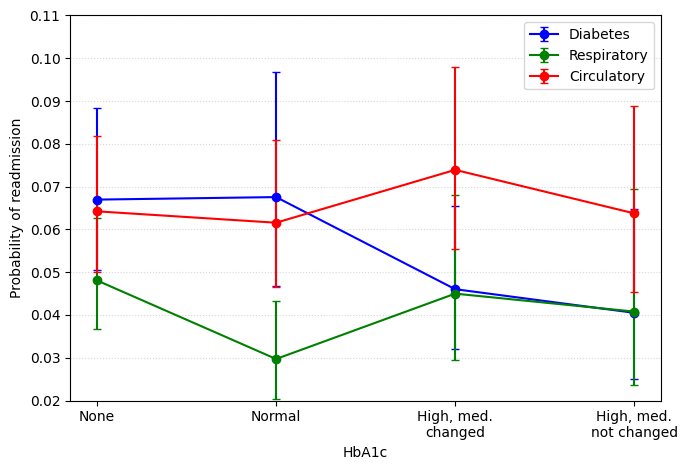

In [25]:
x_order = [
    "No test was performed",
    "Normal result of the test",
    "Result was high and the diabetic medication was changed",
    "Result was high but the diabetic medication was not changed"
]

x_map = {label: i for i, label in enumerate(x_order)}


label_map = {
    "No test was performed": "None",
    "Normal result of the test": "Normal",
    "Result was high and the diabetic medication was changed": "High, med.\nchanged",
    "Result was high but the diabetic medication was not changed": "High, med.\nnot changed"
}

diag_order = ["Diabetes", "Respiratory", "Circulatory"]
diag_colors = {
    "Diabetes": "blue",
    "Respiratory": "green",
    "Circulatory": "red"
}

plt.figure(figsize=(7, 4.8))

for diag in diag_order:
    sub = fig1_grid[fig1_grid["primary_diag_group"] == diag].copy()
    sub["x"] = sub["hba1c_group"].astype(str).map(x_map)
    sub = sub.sort_values("x")

    y = sub["pred_prob"].to_numpy()
    yerr = np.vstack([
        y - sub["lower_ci"].to_numpy(),
        sub["upper_ci"].to_numpy() - y
    ])

    plt.errorbar(
        sub["x"],
        y,
        yerr=yerr,
        fmt="o-",
        capsize=3,
        label=diag,
        color=diag_colors[diag]
    )


plt.xticks(range(len(x_order)), [label_map[x] for x in x_order])
plt.xlabel("HbA1c")
plt.ylabel("Probability of readmission")
plt.ylim(0.02, 0.11)
plt.grid(axis="y", linestyle=":", alpha=0.5)
plt.legend()



plt.tight_layout()

output_dir = Path("../../images/results")
output_dir.mkdir(parents=True, exist_ok=True)

fig = plt.gcf()
fig.savefig(
    output_dir / "hba1c_replication_figure1.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()


In [26]:
fig2_paper = df.copy()

fig2_paper["readmitted_any"] = (fig2_paper["readmitted"] != "NO").astype(int)

fig2_paper = fig2_paper[fig2_paper["gender"].isin(["Female", "Male"])].copy()
fig2_paper = fig2_paper[~fig2_paper["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])].copy()

age_order = [
    "[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)",
    "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"
]

fig2_paper = fig2_paper[fig2_paper["age"].isin(age_order)].copy()

age_plot_paper = (
    fig2_paper.groupby("age", observed=False)["readmitted_any"]
    .mean()
    .reindex(age_order)
    .to_frame("p")
)

age_plot_paper["log_p"] = np.log(age_plot_paper["p"].clip(1e-6, 1 - 1e-6))
print(age_plot_paper)


                 p     log_p
age                         
[0-10)    0.181250 -1.707878
[10-20)   0.382609 -0.960742
[20-30)   0.452395 -0.793199
[30-40)   0.428002 -0.848627
[40-50)   0.447486 -0.804110
[50-60)   0.444197 -0.811487
[60-70)   0.470623 -0.753698
[70-80)   0.494177 -0.704862
[80-90)   0.503590 -0.685993
[90-100)  0.430668 -0.842417


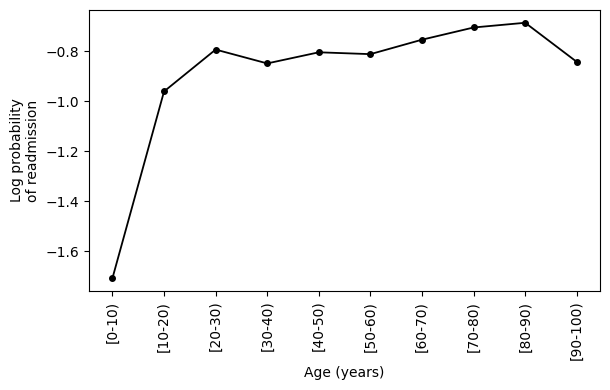

In [27]:
plt.figure(figsize=(6.2, 4.0))
plt.plot(
    range(len(age_plot_paper)),
    age_plot_paper["log_p"],
    "-o",
    color="black",
    linewidth=1.3,
    markersize=4
)
plt.xticks(range(len(age_plot_paper)), age_plot_paper.index, rotation=90)
plt.xlabel("Age (years)")
plt.ylabel("Log probability\nof readmission")
plt.tight_layout()
plt.show()


In [28]:
mean_los = analysis_df["time_in_hospital"].mean()

diag_groups = ["Diabetes", "Other", "Digestive", "Respiratory", "Circulatory"]
hba1c_order = [
    "No test was performed",
    "Normal result of the test",
    "Result was high and the diabetic medication was changed",
    "Result was high but the diabetic medication was not changed"
]

fig3a_grid = pd.DataFrame({
    "primary_diag_group": np.repeat(diag_groups, len(hba1c_order)),
    "hba1c_group": hba1c_order * len(diag_groups),
    "gender": ["Female"] * (len(diag_groups) * len(hba1c_order)),
    "race_group": ["African American"] * (len(diag_groups) * len(hba1c_order)),
    "admission_source_group": ["Admitted from emergency room"] * (len(diag_groups) * len(hba1c_order)),
    "discharge_group": ["Discharged to home"] * (len(diag_groups) * len(hba1c_order)),
    "specialty_group": ["Cardiology"] * (len(diag_groups) * len(hba1c_order)),
    "age_group3": ["30-60 years old"] * (len(diag_groups) * len(hba1c_order)),
    "time_in_hospital": [mean_los] * (len(diag_groups) * len(hba1c_order))
})

def apply_model_categories(new_df, model):
    """Align categorical levels with the fitted Patsy design information."""
    for factor, info in model.model.data.design_info.factor_infos.items():
        col = factor.name()
        if col in new_df.columns and info.type == "categorical":
            new_df[col] = pd.Categorical(new_df[col], categories=info.categories)
    return new_df

fig3a_grid = apply_model_categories(fig3a_grid, final_model)

X_new = build_design_matrices(
    [final_model.model.data.design_info],
    fig3a_grid,
    return_type="dataframe"
)[0]

linpred = np.dot(X_new, final_model.params)
cov = final_model.cov_params()
se_linpred = np.sqrt(np.sum(np.dot(X_new, cov) * X_new, axis=1))

invlogit = lambda x: 1 / (1 + np.exp(-x))
z = 1.96

fig3a_grid["pred_prob"] = invlogit(linpred)
fig3a_grid["lower_ci"] = invlogit(linpred - z * se_linpred)
fig3a_grid["upper_ci"] = invlogit(linpred + z * se_linpred)

print(fig3a_grid[["primary_diag_group", "hba1c_group", "pred_prob", "lower_ci", "upper_ci"]])


   primary_diag_group                                        hba1c_group  \
0            Diabetes                              No test was performed   
1            Diabetes                          Normal result of the test   
2            Diabetes  Result was high and the diabetic medication wa...   
3            Diabetes  Result was high but the diabetic medication wa...   
4               Other                              No test was performed   
5               Other                          Normal result of the test   
6               Other  Result was high and the diabetic medication wa...   
7               Other  Result was high but the diabetic medication wa...   
8           Digestive                              No test was performed   
9           Digestive                          Normal result of the test   
10          Digestive  Result was high and the diabetic medication wa...   
11          Digestive  Result was high but the diabetic medication wa...   
12        Re

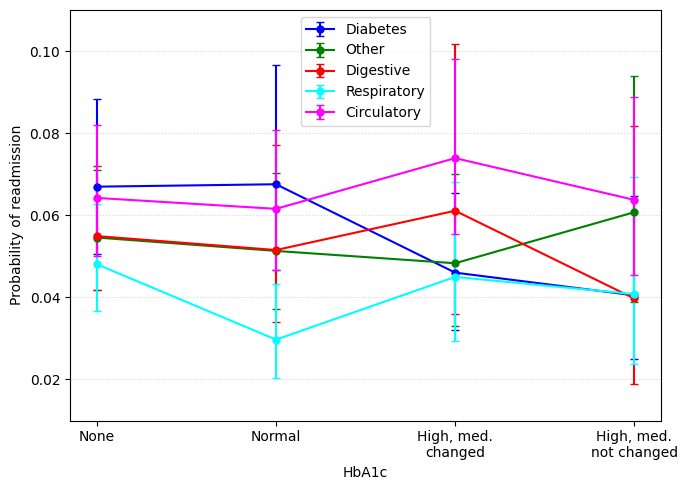

In [29]:
x_map = {label: i for i, label in enumerate(hba1c_order)}

label_map = {
    "No test was performed": "None",
    "Normal result of the test": "Normal",
    "Result was high and the diabetic medication was changed": "High, med.\nchanged",
    "Result was high but the diabetic medication was not changed": "High, med.\nnot changed"
}

diag_order = ["Diabetes", "Other", "Digestive", "Respiratory", "Circulatory"]
diag_colors = {
    "Diabetes": "blue",
    "Other": "green",
    "Digestive": "red",
    "Respiratory": "cyan",
    "Circulatory": "magenta"
}

plt.figure(figsize=(7, 5))

for diag in diag_order:
    sub = fig3a_grid[fig3a_grid["primary_diag_group"] == diag].copy()
    sub["x"] = sub["hba1c_group"].astype(str).map(x_map)
    sub = sub.sort_values("x")

    y = sub["pred_prob"].to_numpy()
    yerr = np.vstack([
        y - sub["lower_ci"].to_numpy(),
        sub["upper_ci"].to_numpy() - y
    ])

    plt.errorbar(
        sub["x"],
        y,
        yerr=yerr,
        fmt="o-",
        capsize=3,
        label=diag,
        color=diag_colors[diag],
        markersize=5,
        linewidth=1.5
    )

plt.xticks(range(len(hba1c_order)), [label_map[x] for x in hba1c_order])
plt.xlabel("HbA1c")
plt.ylabel("Probability of readmission")
plt.ylim(0.01, 0.11)
plt.grid(axis="y", linestyle=":", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


In [30]:
mean_los = analysis_df["time_in_hospital"].mean()

diag_groups_b = ["Diabetes", "Genitourinary", "Injury", "Musculoskeletal", "Neoplasms"]
hba1c_order = [
    "No test was performed",
    "Normal result of the test",
    "Result was high and the diabetic medication was changed",
    "Result was high but the diabetic medication was not changed"
]

fig3b_grid = pd.DataFrame({
    "primary_diag_group": np.repeat(diag_groups_b, len(hba1c_order)),
    "hba1c_group": hba1c_order * len(diag_groups_b),
    "gender": ["Female"] * (len(diag_groups_b) * len(hba1c_order)),
    "race_group": ["African American"] * (len(diag_groups_b) * len(hba1c_order)),
    "admission_source_group": ["Admitted from emergency room"] * (len(diag_groups_b) * len(hba1c_order)),
    "discharge_group": ["Discharged to home"] * (len(diag_groups_b) * len(hba1c_order)),
    "specialty_group": ["Cardiology"] * (len(diag_groups_b) * len(hba1c_order)),
    "age_group3": ["30-60 years old"] * (len(diag_groups_b) * len(hba1c_order)),
    "time_in_hospital": [mean_los] * (len(diag_groups_b) * len(hba1c_order))
})

def apply_model_categories(new_df, model):
    """Align categorical levels with the fitted Patsy design information."""
    for factor, info in model.model.data.design_info.factor_infos.items():
        col = factor.name()
        if col in new_df.columns and info.type == "categorical":
            new_df[col] = pd.Categorical(new_df[col], categories=info.categories)
    return new_df

fig3b_grid = apply_model_categories(fig3b_grid, final_model)

X_new = build_design_matrices(
    [final_model.model.data.design_info],
    fig3b_grid,
    return_type="dataframe"
)[0]

linpred = np.dot(X_new, final_model.params)
cov = final_model.cov_params()
se_linpred = np.sqrt(np.sum(np.dot(X_new, cov) * X_new, axis=1))

invlogit = lambda x: 1 / (1 + np.exp(-x))
z = 1.96

fig3b_grid["pred_prob"] = invlogit(linpred)
fig3b_grid["lower_ci"] = invlogit(linpred - z * se_linpred)
fig3b_grid["upper_ci"] = invlogit(linpred + z * se_linpred)

print(fig3b_grid[["primary_diag_group", "hba1c_group", "pred_prob", "lower_ci", "upper_ci"]])


   primary_diag_group                                        hba1c_group  \
0            Diabetes                              No test was performed   
1            Diabetes                          Normal result of the test   
2            Diabetes  Result was high and the diabetic medication wa...   
3            Diabetes  Result was high but the diabetic medication wa...   
4       Genitourinary                              No test was performed   
5       Genitourinary                          Normal result of the test   
6       Genitourinary  Result was high and the diabetic medication wa...   
7       Genitourinary  Result was high but the diabetic medication wa...   
8              Injury                              No test was performed   
9              Injury                          Normal result of the test   
10             Injury  Result was high and the diabetic medication wa...   
11             Injury  Result was high but the diabetic medication wa...   
12    Muscul

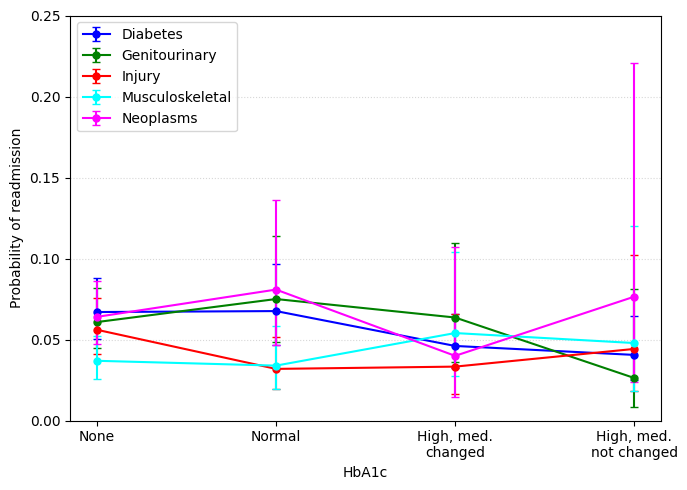

In [31]:
x_map = {label: i for i, label in enumerate(hba1c_order)}

label_map = {
    "No test was performed": "None",
    "Normal result of the test": "Normal",
    "Result was high and the diabetic medication was changed": "High, med.\nchanged",
    "Result was high but the diabetic medication was not changed": "High, med.\nnot changed"
}

diag_order_b = ["Diabetes", "Genitourinary", "Injury", "Musculoskeletal", "Neoplasms"]
diag_colors_b = {
    "Diabetes": "blue",
    "Genitourinary": "green",
    "Injury": "red",
    "Musculoskeletal": "cyan",
    "Neoplasms": "magenta"
}

plt.figure(figsize=(7, 5))

for diag in diag_order_b:
    sub = fig3b_grid[fig3b_grid["primary_diag_group"] == diag].copy()
    sub["x"] = sub["hba1c_group"].astype(str).map(x_map)
    sub = sub.sort_values("x")

    y = sub["pred_prob"].to_numpy()
    yerr = np.vstack([
        y - sub["lower_ci"].to_numpy(),
        sub["upper_ci"].to_numpy() - y
    ])

    plt.errorbar(
        sub["x"],
        y,
        yerr=yerr,
        fmt="o-",
        capsize=3,
        label=diag,
        color=diag_colors_b[diag],
        markersize=5,
        linewidth=1.5
    )

plt.xticks(range(len(hba1c_order)), [label_map[x] for x in hba1c_order])
plt.xlabel("HbA1c")
plt.ylabel("Probability of readmission")
plt.ylim(0.0, 0.25)
plt.grid(axis="y", linestyle=":", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


## Interpretation

This is a full-cohort inferential replication, not a held-out prediction experiment. The reconstructed model retained the source study's interaction-dependent pattern between HbA1c category and primary diagnosis, but several confidence intervals overlap. The fitted associations and predicted probabilities are therefore descriptive and conditional on the model specification; they do not estimate causal effects or out-of-sample performance.
